# 01 – Adatforrások és CSV-fájlok feltárása

## A notebook célja

A Balaton 2016–2026 közötti vízállás- és vízhőmérséklet-adatainak első, migráció előtti vizsgálata.

Ebben a lépésben még **nem módosítjuk és nem szűrjük az adatokat**. A feladat a nyers CSV-fájlok szerkezetének feltárása:
- a fájlok listázása és elnevezésük ellenőrzése;
- a fájlok kódolásának és mezőelválasztójának felismerése;
- oszlopnevek és adattípusok megtekintése;
- hiányzó értékek és néhány minta rekord vizsgálata.

A következő migrációs notebookot a most feltárt tényleges adatszerkezet alapján készítjük el.

**Adatkezelési alapelv:** a `Raw_data_2016-2026` könyvtárban található eredeti fájlokat változatlanul hagyjuk.


## 1. Projektkönyvtár és adatforrás beállítása

A notebook a felhasználó által megadott Windows-mappából olvassa be a CSV-fájlokat. Ha a projektet másik gépen vagy másik könyvtárban nyitjuk meg, csak az alábbi útvonalat kell módosítani.


In [1]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT"
)

RAW_DIR = PROJECT_DIR / "Raw_data_2016-2026"

print("Projektkönyvtár:", PROJECT_DIR)
print("Nyers adatok:", RAW_DIR)
print("Projektkönyvtár létezik:", PROJECT_DIR.exists())
print("Nyers adatkönyvtár létezik:", RAW_DIR.exists())

if not RAW_DIR.exists():
    raise FileNotFoundError(
        f"Nem található a nyers adatokat tartalmazó könyvtár: {RAW_DIR}"
    )


Projektkönyvtár: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT
Nyers adatok: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\Raw_data_2016-2026
Projektkönyvtár létezik: True
Nyers adatkönyvtár létezik: True


## 2. CSV-fájlok listázása

A fájlnevek a megadott `2025-26.csv` mintát követik. A keresés minden CSV-fájlt kilistáz, majd külön jelzi azokat, amelyek neve megfelel az évpár-formátumnak.

In [2]:
import re
import pandas as pd

all_csv_files = sorted(RAW_DIR.glob("*.csv"))

filename_pattern = re.compile(r"^\d{4}-\d{2}\.csv$", flags=re.IGNORECASE)
matching_files = [
    path for path in all_csv_files
    if filename_pattern.match(path.name)
]

file_inventory = pd.DataFrame({
    "fájlnév": [p.name for p in all_csv_files],
    "méret_byte": [p.stat().st_size for p in all_csv_files],
    "méret_kB": [round(p.stat().st_size / 1024, 1) for p in all_csv_files],
    "méret_MB": [round(p.stat().st_size / (1024 ** 2), 3) for p in all_csv_files],
    "név_minta_megfelel": [
        bool(filename_pattern.match(p.name)) for p in all_csv_files
    ]
})

display(file_inventory)

print(f"Összes CSV-fájl: {len(all_csv_files)}")
print(f"A megadott névmintának megfelelő fájl: {len(matching_files)}")

if not all_csv_files:
    raise FileNotFoundError("A megadott könyvtárban nem található CSV-fájl.")


,fájlnév,méret_byte,méret_kB,méret_MB,név_minta_megfelel
0,2016-17.csv,234349,228.9,0.223,True
1,2017-18.csv,225986,220.7,0.216,True
2,2018-19.csv,228477,223.1,0.218,True
3,2019-20.csv,242550,236.9,0.231,True
4,2020-21.csv,234057,228.6,0.223,True
5,2021-22.csv,609388,595.1,0.581,True
6,2022-23.csv,779977,761.7,0.744,True
7,2023-24.csv,768890,750.9,0.733,True
8,2024-25.csv,756090,738.4,0.721,True
9,2025-26.csv,737319,720.0,0.703,True


Összes CSV-fájl: 10
A megadott névmintának megfelelő fájl: 10


## 2/A. A CSV-fájlok méretének időbeli változása

A nyers CSV-fájlok méretét külön is megvizsgáljuk. A felhasználói előzetes megfigyelés szerint 2021-től megváltozott a fájlok mérete.

Ebben a szakaszban kizárólag a **fájlméret-változás tényét** rögzítjük:
- megjelenítjük az egyes fájlok méretét;
- összehasonlítjuk a 2021 előtti és a 2021-től kezdődő fájlokat;
- ábrán is bemutatjuk az időbeli különbséget.

A fájlméret önmagában nem bizonyítja a mérési gyakoriság megváltozását. A mérési gyakoriságra vonatkozó következtetést most nem vonunk le; azt később, a rekordok és időbélyegek vizsgálatával lehet ellenőrizni.

In [3]:
# A fájlnév első négy karakteréből képezzük a kezdőévet.
# Példa: 2025-26.csv -> 2025
size_rows = []

for file_path in matching_files:
    start_year = int(file_path.name[:4])
    size_rows.append({
        "fájlnév": file_path.name,
        "kezdőév": start_year,
        "méret_byte": file_path.stat().st_size,
        "méret_kB": file_path.stat().st_size / 1024,
        "méret_MB": file_path.stat().st_size / (1024 ** 2)
    })

file_size_df = (
    pd.DataFrame(size_rows)
    .sort_values("kezdőév")
    .reset_index(drop=True)
)

display(
    file_size_df.assign(
        méret_kB=lambda x: x["méret_kB"].round(1),
        méret_MB=lambda x: x["méret_MB"].round(3)
    )
)

before_2021 = file_size_df.loc[file_size_df["kezdőév"] < 2021, "méret_kB"]
from_2021 = file_size_df.loc[file_size_df["kezdőév"] >= 2021, "méret_kB"]

print("Fájlméret-összehasonlítás (kB):")
print(f"2021 előtti fájlok száma: {len(before_2021)}")
print(f"2021-től kezdődő fájlok száma: {len(from_2021)}")

if not before_2021.empty:
    print(f"2021 előtti fájlok medián mérete: {before_2021.median():,.1f} kB")
if not from_2021.empty:
    print(f"2021-től kezdődő fájlok medián mérete: {from_2021.median():,.1f} kB")

if not before_2021.empty and not from_2021.empty:
    ratio = from_2021.median() / before_2021.median()
    print(f"A két időszak medián fájlméretének aránya: {ratio:.2f}")


,fájlnév,kezdőév,méret_byte,méret_kB,méret_MB
0,2016-17.csv,2016,234349,228.9,0.223
1,2017-18.csv,2017,225986,220.7,0.216
2,2018-19.csv,2018,228477,223.1,0.218
3,2019-20.csv,2019,242550,236.9,0.231
4,2020-21.csv,2020,234057,228.6,0.223
5,2021-22.csv,2021,609388,595.1,0.581
6,2022-23.csv,2022,779977,761.7,0.744
7,2023-24.csv,2023,768890,750.9,0.733
8,2024-25.csv,2024,756090,738.4,0.721
9,2025-26.csv,2025,737319,720.0,0.703


Fájlméret-összehasonlítás (kB):
2021 előtti fájlok száma: 5
2021-től kezdődő fájlok száma: 5
2021 előtti fájlok medián mérete: 228.6 kB
2021-től kezdődő fájlok medián mérete: 738.4 kB
A két időszak medián fájlméretének aránya: 3.23


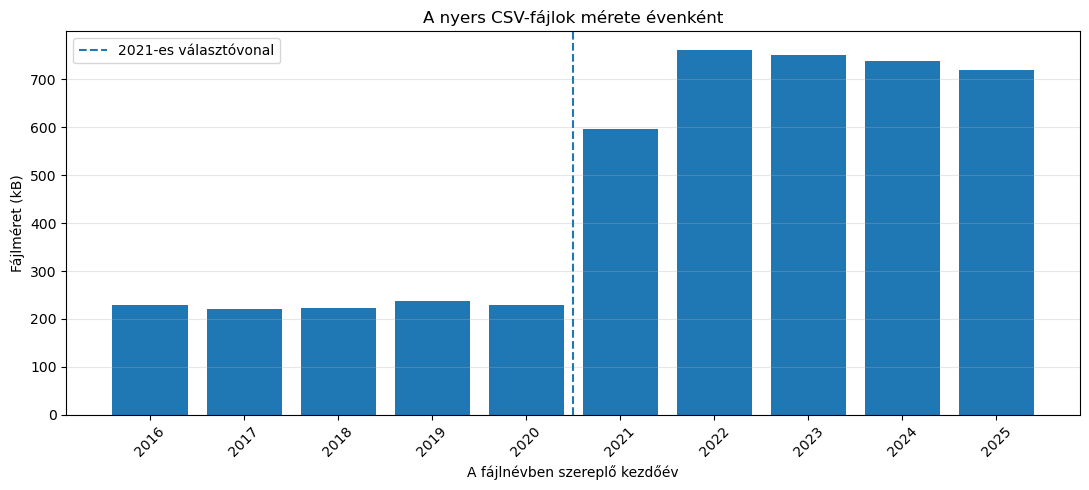

In [4]:
import matplotlib.pyplot as plt

if not file_size_df.empty:
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(
        file_size_df["kezdőév"].astype(str),
        file_size_df["méret_kB"]
    )
    ax.axvline(
        x=sum(file_size_df["kezdőév"] < 2021) - 0.5,
        linestyle="--",
        linewidth=1.5,
        label="2021-es választóvonal"
    )
    ax.set_title("A nyers CSV-fájlok mérete évenként")
    ax.set_xlabel("A fájlnévben szereplő kezdőév")
    ax.set_ylabel("Fájlméret (kB)")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


**A notebookban rögzítendő megállapítás:** a fájlméretek 2021 előtti és 2021-től kezdődő értékeit külön bemutatjuk. Ha a méretkülönbség látható, azt a további vizsgálatok szempontjából releváns adatjellemzőként kezeljük.

Ebből a fájlméret-vizsgálatból önmagában nem következik, hogy 2021-től megváltozott a mérés gyakorisága, és az sem, hogy az éves adatok száma pontosan milyen mértékben nőtt. Ezeket a rekordok számának és az időbélyegeknek a későbbi vizsgálata igazolhatja vagy cáfolhatja.

## 3. Beolvasási beállítások tesztelése

A CSV-fájloknál előzetesen nem feltételezzük sem a kódolást, sem az elválasztójelet. A következő kód több gyakori beállítást próbál ki, és az első sikeres beolvasást használja.

A felismerés eredményét minden fájlnál eltároljuk, hogy a migráció során dokumentálható legyen, milyen beállításokkal történt a beolvasás.


In [5]:
ENCODINGS = ["utf-8-sig", "cp1250", "latin2", "utf-8"]
SEPARATORS = [";", ",", "\t"]

def read_csv_with_detection(file_path):
    """CSV beolvasása több lehetséges kódolás és elválasztó kipróbálásával."""
    attempts = []

    for encoding in ENCODINGS:
        for separator in SEPARATORS:
            try:
                df = pd.read_csv(
                    file_path,
                    sep=separator,
                    encoding=encoding,
                    engine="python"
                )

                # Egyetlen oszlop esetén valószínű, hogy nem megfelelő az elválasztó.
                if df.shape[1] > 1:
                    return df, encoding, separator, attempts

                attempts.append(
                    f"{encoding}, {repr(separator)}: csak egy oszlop"
                )

            except Exception as exc:
                attempts.append(
                    f"{encoding}, {repr(separator)}: {type(exc).__name__}: {exc}"
                )

    raise ValueError(
        f"Nem sikerült megfelelő beállítással beolvasni: {file_path.name}\n"
        + "\n".join(attempts)
    )


## 4. A fájlok szerkezetének áttekintése

Fájlonként megvizsgáljuk az oszlopok számát, az oszlopneveket, az adattípusokat, a hiányzó értékeket és az első néhány rekordot.

In [6]:
inspection_results = {}
summary_rows = []

for file_path in all_csv_files:
    df, encoding, separator, attempts = read_csv_with_detection(file_path)
    inspection_results[file_path.name] = {
        "dataframe": df,
        "encoding": encoding,
        "separator": separator
    }

    summary_rows.append({
        "fájlnév": file_path.name,
        "sorok_száma": len(df),
        "oszlopok_száma": len(df.columns),
        "oszlopnevek": " | ".join(map(str, df.columns)),
        "kódolás": encoding,
        "elválasztó": repr(separator)
    })

    print("=" * 90)
    print("Fájl:", file_path.name)
    print("Kódolás:", encoding, "| Elválasztó:", repr(separator))
    print("Oszlopok és adattípusok:")
    display(pd.DataFrame({
        "oszlop": df.columns.astype(str),
        "adattípus": [str(dtype) for dtype in df.dtypes],
        "hiányzó_értékek": df.isna().sum().values
    }))
    print("Első 5 rekord:")
    display(df.head())

inspection_summary = pd.DataFrame(summary_rows)
display(inspection_summary)


Fájl: 2016-17.csv
Kódolás: utf-8-sig | Elválasztó: ';'
Oszlopok és adattípusok:


,oszlop,adattípus,hiányzó_értékek
0,Időpont,object,0
1,Siófok [2888]\n Felszíni vízállás (cm),int64,0
2,Siófok [2888]\n Vízhő a vízfelszín közelében (C),object,10381


Első 5 rekord:


,Időpont,Siófok [2888]\n Felszíni vízállás (cm),Siófok [2888]\n Vízhő a vízfelszín közelében (C)
0,2016-09-30 00:30,113,NaN
1,2016-09-30 04:15,113,NaN
2,2016-09-30 06:45,115,NaN
3,2016-09-30 07:00,114,"18,5"
4,2016-09-30 07:15,113,NaN


Fájl: 2017-18.csv
Kódolás: utf-8-sig | Elválasztó: ';'
Oszlopok és adattípusok:


,oszlop,adattípus,hiányzó_értékek
0,Időpont,object,0
1,Siófok [2888]\n Felszíni vízállás (cm),int64,0
2,Siófok [2888]\n Vízhő a vízfelszín közelében (C),object,10337


... (31 outputs left out)

,oszlop,adattípus,hiányzó_értékek
0,Időpont,object,0
1,Siófok [2888]\n Felszíni vízállás (cm),float64,1
2,Siófok [2888]\n Vízhő a vízfelszín közelében (C),object,34683


Első 5 rekord:


,Időpont,Siófok [2888]\n Felszíni vízállás (cm),Siófok [2888]\n Vízhő a vízfelszín közelében (C)
0,2025-09-30 00:00,72.0,NaN
1,2025-09-30 00:15,72.0,NaN
2,2025-09-30 00:30,72.0,NaN
3,2025-09-30 00:45,71.0,NaN
4,2025-09-30 01:00,72.0,NaN


,fájlnév,sorok_száma,oszlopok_száma,oszlopnevek,kódolás,elválasztó
0,2016-17.csv,10681,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
1,2017-18.csv,10341,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
2,2018-19.csv,10380,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
3,2019-20.csv,11068,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
4,2020-21.csv,10664,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
5,2021-22.csv,28186,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
6,2022-23.csv,35109,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
7,2023-24.csv,35209,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
8,2024-25.csv,35122,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'
9,2025-26.csv,35045,3,Időpont | Siófok [2888]\n Felszíni vízállás (c...,utf-8-sig,';'


## 5. Az oszlopszerkezetek összehasonlítása

A migráció előtt ellenőrizni kell, hogy az egyes évek fájljai azonos oszlopszerkezetűek-e. Az eltérő oszlopnevek vagy oszlopszámok külön kezelést igényelhetnek.


In [7]:
schema_rows = []

for file_name, result in inspection_results.items():
    df = result["dataframe"]
    schema_rows.append({
        "fájlnév": file_name,
        "oszlopnevek": tuple(map(str, df.columns)),
        "oszlopszám": len(df.columns)
    })

schema_df = pd.DataFrame(schema_rows)
display(schema_df)

distinct_schemas = schema_df["oszlopnevek"].drop_duplicates().tolist()
print("Eltérő oszlopszerkezetek száma:", len(distinct_schemas))

if len(distinct_schemas) == 1:
    print("A vizsgált fájlok oszlopszerkezete egységes.")
else:
    print("FIGYELEM: a fájlok oszlopszerkezete eltér. Migráció előtt egyeztetni kell.")


,fájlnév,oszlopnevek,oszlopszám
0,2016-17.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
1,2017-18.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
2,2018-19.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
3,2019-20.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
4,2020-21.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
5,2021-22.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
6,2022-23.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
7,2023-24.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
8,2024-25.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3
9,2025-26.csv,"(Időpont, Siófok [2888]\n Felszíni vízállás (c...",3


Eltérő oszlopszerkezetek száma: 1
A vizsgált fájlok oszlopszerkezete egységes.


## 6. Hiányzó értékek áttekintése

Ez a vizsgálat még nem szűri ki a hiányos rekordokat. A cél annak megállapítása, hogy mely oszlopokban és milyen mértékben fordulnak elő hiányzó értékek.


In [8]:
missing_rows = []

for file_name, result in inspection_results.items():
    df = result["dataframe"]
    for column in df.columns:
        missing_rows.append({
            "fájlnév": file_name,
            "oszlop": str(column),
            "rekordok_száma": len(df),
            "hiányzó_értékek": int(df[column].isna().sum()),
            "hiányzó_arány_%": (
                round(df[column].isna().mean() * 100, 2)
                if len(df) else None
            )
        })

missing_summary = pd.DataFrame(missing_rows)
display(missing_summary)


,fájlnév,oszlop,rekordok_száma,hiányzó_értékek,hiányzó_arány_%
0,2016-17.csv,Időpont,10681,0,0.00
1,2016-17.csv,Siófok [2888]\n Felszíni vízállás (cm),10681,0,0.00
2,2016-17.csv,Siófok [2888]\n Vízhő a vízfelszín közelében (C),10681,10381,97.19
3,2017-18.csv,Időpont,10341,0,0.00
4,2017-18.csv,Siófok [2888]\n Felszíni vízállás (cm),10341,0,0.00
5,2017-18.csv,Siófok [2888]\n Vízhő a vízfelszín közelében (C),10341,10337,99.96
6,2018-19.csv,Időpont,10380,0,0.00
7,2018-19.csv,Siófok [2888]\n Felszíni vízállás (cm),10380,0,0.00
8,2018-19.csv,Siófok [2888]\n Vízhő a vízfelszín közelében (C),10380,10378,99.98
9,2019-20.csv,Időpont,11068,0,0.00


## 7. Fájlonkénti adatminőségi összesítő

Ebben a táblázatban minden CSV-fájlról egyetlen összesítő sort készítünk. A cél, hogy összehasonlíthatóvá váljon az egyes időszakok adatmennyisége és a két mérési változó teljessége.

A táblázat tartalmazza:
- a fájl nevét és az abból kiolvasható időszakot;
- a fájl méretét;
- a rekordok számát;
- a vízállás hiányzó értékeinek számát;
- a vízhőmérséklet hiányzó értékeinek számát.

A fejlécben szereplő pontos oszlopneveket a korábbi vizsgálatban azonosítottuk. A kód ezek alapján keresi meg a vízállás- és vízhőmérséklet-oszlopot. Ha valamelyik fájlban eltérő oszlopnév szerepel, a program hibát jelez, nem próbálja találgatással megfeleltetni.


In [9]:
# A tényleges oszlopnevek megkeresése.
DATETIME_COL = "Időpont"

def find_column(columns, required_text):
    matches = [
        col for col in columns
        if required_text.casefold() in str(col).replace("\n", " ").casefold()
    ]
    if len(matches) != 1:
        raise ValueError(
            f"A(z) '{required_text}' részlet alapján {len(matches)} oszlop található: "
            f"{matches}. Ellenőrizd a fájl oszlopneveit."
        )
    return matches[0]

file_summary_rows = []

for file_path in all_csv_files:
    # Az előző szakaszban beolvasott DataFrame-et használjuk.
    df = inspection_results[file_path.name]["dataframe"]

    if DATETIME_COL not in df.columns:
        raise ValueError(
            f"A(z) {file_path.name} fájlban nem található a '{DATETIME_COL}' oszlop."
        )

    water_level_col = find_column(df.columns, "Felszíni vízállás")
    water_temp_col = find_column(df.columns, "Vízhő a vízfelszín közelében")

    file_summary_rows.append({
        "fájlnév": file_path.name,
        "időszak": file_path.stem,
        "fájlméret_kB": round(file_path.stat().st_size / 1024, 1),
        "rekordok_száma": len(df),
        "vízállás_hiányzó": int(df[water_level_col].isna().sum()),
        "vízhőmérséklet_hiányzó": int(df[water_temp_col].isna().sum())
    })

file_quality_summary = (
    pd.DataFrame(file_summary_rows)
    .sort_values("fájlnév")
    .reset_index(drop=True)
)

display(file_quality_summary)

print("Összes vizsgált fájl:", len(file_quality_summary))
print("Összes rekord:", f"{file_quality_summary['rekordok_száma'].sum():,}")
print(
    "Összes hiányzó vízhőmérsékleti érték:",
    f"{file_quality_summary['vízhőmérséklet_hiányzó'].sum():,}"
)


,fájlnév,időszak,fájlméret_kB,rekordok_száma,vízállás_hiányzó,vízhőmérséklet_hiányzó
0,2016-17.csv,2016-17,228.9,10681,0,10381
1,2017-18.csv,2017-18,220.7,10341,0,10337
2,2018-19.csv,2018-19,223.1,10380,0,10378
3,2019-20.csv,2019-20,236.9,11068,0,11067
4,2020-21.csv,2020-21,228.6,10664,0,10391
5,2021-22.csv,2021-22,595.1,28186,0,27822
6,2022-23.csv,2022-23,761.7,35109,0,34749
7,2023-24.csv,2023-24,750.9,35209,0,34845
8,2024-25.csv,2024-25,738.4,35122,2,34757
9,2025-26.csv,2025-26,720.0,35045,1,34683


Összes vizsgált fájl: 10
Összes rekord: 221,805
Összes hiányzó vízhőmérsékleti érték: 219,410


In [10]:
# Az összesítő táblázatot külön CSV-fájlba is elmentjük,
# hogy később a projekt dokumentációjában és a GitHubon is felhasználható legyen.
SUMMARY_DIR = PROJECT_DIR / "reports"
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

summary_output = SUMMARY_DIR / "01_fajlonkenti_adatminosegi_osszefoglalo.csv"
file_quality_summary.to_csv(
    summary_output,
    index=False,
    encoding="utf-8-sig",
    sep=";"
)

print("Az összesítő táblázat mentési helye:")
print(summary_output)


Az összesítő táblázat mentési helye:
C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\reports\01_fajlonkenti_adatminosegi_osszefoglalo.csv


### Az összesítő értelmezése

Az összesítő alapján külön kell választani:
- **az adatmennyiséget**, amelyet a rekordok száma jelez;
- **az adatok teljességét**, amelyet a hiányzó vízállás- és vízhőmérséklet-értékek mutatnak;
- **a fájlméretet**, amely önmagában nem bizonyítja a mérési gyakoriság változását.

A 2021 előtti és a 2021-től kezdődő időszakok összehasonlítása a táblázatból elvégezhető, de a mérési gyakoriság megváltozását csak a dátum-idő értékek és a rekordok időbeli eloszlásának külön vizsgálata igazolhatja.


## 8. A vizsgálat eredményének rögzítése

A következő migrációs lépés előtt a notebook eredményei alapján rögzítjük:
- melyik oszlop tartalmazza a dátumot;
- melyik oszlop tartalmazza a vízállást;
- melyik oszlop tartalmazza a vízhőmérsékletet;
- vannak-e eltérő szerkezetű fájlok;
- milyen kódolást és elválasztójelet kell használni.
